# T06 · Metadata APIs, self-similarity & novelty, Essentia models, completeness
*Music Information Retrieval & Machine Learning for Audio · TU Berlin · WiSe 2026/27*

| Block | Topic |
|---|---|
| 0 | Setup |
| 1 | Metadata APIs - basic pattern, fuzzy matching + Discogs example |
| 2 | Self-similarity matrix & Foote novelty |
| 3 | Installing and using the Essentia mood classifiers |
| 4 | Completeness of metadata retake |
| 5 | MusicBrainz API: ISRC lookup, artist type & gender |

*Cyanite* (audio-based tags for Spotify IDs) is not part of this notebook: the script `cyanite_v7_harvest.py`
is provided separately on ISIS, in case you prefer to use this solution - you will need your own Cyanite token, usage is described at the top of the script.

---
## 0 · Setup
**Three new packages**, all on conda-forge. In a terminal (Miniforge Prompt / Terminal), in your course environment:
```bash
conda activate mirml                                           # ... or how you named your env
conda install python3-discogs-client musicbrainzngs rapidfuzz onnxruntime  # from conda-forge, no pip needed
python -c "import discogs_client, musicbrainzngs, rapidfuzz, onnxruntime; print('ok')"
```
- Afterwards add the packages to your `environment.yml` (under `dependencies:`).

**Discogs token** (free): log in on discogs.com → *Settings → Developers → Generate new token*.
Never paste a token into a code cell – it would end up in your submission or on GitHub.
The notebook asks for it in a hidden input field. Optionally store it once as an environment variable `DISCOGS_TOKEN`,
then the notebook finds it by itself:
- Windows (PowerShell): `setx DISCOGS_TOKEN "your-token"`
- macOS (Terminal): `echo 'export DISCOGS_TOKEN="your-token"' >> ~/.zshrc`

and restart your IDE. **MusicBrainz** needs no token.

In [1]:
# Standard library
import os
import re
import sys
from getpass import getpass
from importlib.metadata import version
from pathlib import Path

# Third-party
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import discogs_client                         # conda/pip name: python3-discogs-client
import musicbrainzngs
import json
import urllib.request
import onnxruntime as ort

from rapidfuzz.distance import JaroWinkler
from rapidfuzz.utils import default_process
from scipy.spatial.distance import cdist
from scipy.signal import find_peaks
from IPython.display import Audio, display


print("Python  ", sys.version.split()[0], "|", sys.executable)
for pkg in ("numpy", "pandas", "librosa", "scipy", "python3-discogs-client", "musicbrainzngs", "rapidfuzz", "onnxruntime"):
    print(f"{pkg:<23}", version(pkg))

Python   3.12.16 | /home/hallvard/miniforge3/envs/mirml/bin/python
numpy                   2.5.4
pandas                  3.1.0
librosa                 1.0.0
scipy                   1.18.1
python3-discogs-client  2.10
musicbrainzngs          0.7.1
rapidfuzz               3.14.6
onnxruntime             1.32.0


In [2]:
# ── CONFIG ───────────────────────────────────────────────────────────────
CORPUS_DIR = Path("data") / "nu-disco-disco"   # ← name of your corpus folder
PREVIEW_DIR = CORPUS_DIR / "previews"  # change the folder/directory, if it differs
CONTACT = "hjjensen@campus.tu-berlin.de"  # ← MusicBrainz wants a contact address in the user agent
YEARS = list(range(2019, 2024))            # ← the years YOUR corpus covers, e.g. list(range(2020, 2024))
# ─────────────────────────────────────────────────────────────────────────
SESSION = "T06"
OUTPUT_DIR = Path("output") / SESSION      # results of this session (API caches, tables)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_DEMO = 10                                # number of tracks for the API demo

assert CORPUS_DIR.is_dir(), f"Not found: {CORPUS_DIR.resolve()} → check CORPUS_DIR"
CHART_CSV = next(CORPUS_DIR.glob("*.csv"))  # the full chart metadata of your genre
charts = pd.read_csv(CHART_CSV)

charts = charts[charts["year"].isin(YEARS)]  # from here on: only your years
print(CHART_CSV, "|", charts.shape[0], "rows ×", charts.shape[1], "columns | years", YEARS[0], "–", YEARS[-1])

data/nu-disco-disco/Nu_Disco_Disco.csv | 3813 rows × 14 columns | years 2019 – 2023


---
## 1 · Metadata APIs: the basic pattern + Discogs example
**Ways to get metadata from the web:**

| Way | Example | + | − |
|---|---|---|---|
| **Official API with a Python client** | `python3-discogs-client`, `musicbrainzngs`, `spotipy` | handles URLs, login, pages, rate limits | Doesn't exist for every data source |
| Official API via request | `requests.get(url, params=…).json()` | works for every API | login, pages, limits yourself |
| Data dumps | Discogs monthly XML dumps, MusicBrainz database dumps | complete, no limits | several GB, need parsing |
| Scraping (HTML pages) | `requests` + `BeautifulSoup` | when there is no API (Beatport, Resident Advisor) | breaks when the page changes; check terms of use and `robots.txt` |

→ We use the **Python clients** in this example

**The pattern for every API usage**:
1. **Identify yourself:** token and/or user agent - Tokens stay out of the code.
2. **Rate limit:** Discogs 60 requests/min with token, MusicBrainz 1 request/s.
3. **Query each item only once:** deduplicate first (the same track charts in several years).
4. **Cache every answer immediately** (here: append to a CSV) so you can interrupt at any time and continue where it stopped.
5. **Keep the match scores**, so you can check and filter matches later instead of trusting the first hit.

**Matching**: an exact ID (ISRC, barcode) is ideal but not always available.
Alternative: **fuzzy string matching** of artist / title / label – here with the **Jaro-Winkler similarity**.

In [3]:
# Unique tracks: the same track can chart in several years → query it only once
tracks = (charts[charts["beatport_track_id"] > 0]           # 0 = placeholder for a missing ID
                .drop_duplicates("beatport_track_id")       # only keep unique IDs
                .dropna(subset=["artist", "title"])          # nothing to search for without artist and title
                .loc[:, ["beatport_track_id", "artist", "title", "mix", "label", "isrc"]] # select your desired columns
                .astype({"beatport_track_id": int})
                .reset_index(drop=True))
print(len(charts), "chart entries →", len(tracks), "unique tracks")

demo = tracks.sample(N_DEMO, random_state=SEED)   # small random sample for the tutorial
demo

3813 chart entries → 2925 unique tracks


,beatport_track_id,artist,title,mix,label,isrc
1047,14411866,"Delia Renee, Dave Lee ZR",You're Gonna Want Me Back,Dave Lee ZR Dubwise Revisited,High Fashion Music,NLP432000060
2395,16459906,Faze Action,Body To Body,Original Mix,Faze Action Records,GB3DD2200003
1127,15062700,"The Shapeshifters, Teni Tinks",You Ain't Love feat. Teni Tinks,Express Mix,Glitterbox Recordings,GBCPZ2119498
1392,14985509,"Rampue, Kalipo",Footsteps (feat. Rampue),Original Mix,Ki Records,QM4TW2165320
679,13592961,"Purple Disco Machine, Sophie and the Giants, R...",Hypnotized,Roosevelt Extended Mix,Sweat It Out,AUDCB1701582
1745,15508340,CYRK,Out Of The Pink,Original Mix,Folklor Nation,DEY472174528
2356,16827981,Paul Parsons,Nobody Love Me Like You Do,Original Mix,FUNK SUPREME,DEH742219260
2910,17869149,"Paul Parsons, Adri Block",Feel Like Gettin' Down,Original Mix,MASTERMIX RECORDS,DEPI82311637
1393,15395995,SixxFoot,Lost,Original Mix,NYLO,UKACT2161634
1652,15499238,Da Lukas,Nasty Girl feat. Majuri,Extended Mix,Midnight Riot,UKACT2131445


**Jaro-Winkler similarity** (0 = nothing in common … 1 = identical), made for matching names in record linkage
(Jaro 1989; Winkler 1990):
- **Jaro:** $\text{sim}_J = \frac{1}{3}\left(\frac{m}{|a|} + \frac{m}{|b|} + \frac{m - t}{m}\right)$ with
  $m$ = number of characters of $a$ that also occur in $b$ at *roughly the same position*
  (at most $\lfloor \max(|a|,|b|)/2 \rfloor - 1$ places away) and $t$ = half the number of these characters that are in a different order.
- **Winkler's addition:** $\text{sim}_{JW} = \text{sim}_J + \ell \cdot 0.1 \cdot (1 - \text{sim}_J)$ with
  $\ell$ = length of the common **prefix** (max. 4) – names that start the same way get a bonus (typos are rarer at the beginning).

Alternatives: Levenshtein / edit distance (number of single-character edits), token-based scores
(`rapidfuzz.fuzz.token_sort_ratio` – ignores word order, useful for "B & A" vs. "A & B").

**1. Normalise** the strings (`default_process`: lower case, punctuation removed, trimmed), otherwise "FISHER" and "Fisher" already differ.

In [4]:
def sim(a, b):
    # Jaro-Winkler similarity 0…1 after normalising both strings (lower case, no punctuation, trimmed)
    return JaroWinkler.normalized_similarity(str(a), str(b), processor=default_process)

for a, b in [("Above & Beyond", "Above and Beyond"), ("FISHER", "Fisher (AUS)"),
             ("Charlotte de Witte", "Charlotte De Witte"), ("Tiësto", "Tiesto"), ("Disclosure", "Closure")]:
    print(f"{a!r:22} vs {b!r:20} → {sim(a, b):.2f}")

'Above & Beyond'       vs 'Above and Beyond'   → 0.90
'FISHER'               vs 'Fisher (AUS)'       → 0.91
'Charlotte de Witte'   vs 'Charlotte De Witte' → 1.00
'Tiësto'               vs 'Tiesto'             → 0.91
'Disclosure'           vs 'Closure'            → 0.80


Note the last two: accents are **not** removed, and "Disclosure" vs. "Closure" is low only because the prefix differs.
A threshold is always a trade-off between wrong matches and missed matches.

**Discogs:** `discogs.search(...)` returns search hits that already contain **genre and style**

In [5]:
token = os.environ.get("DISCOGS_TOKEN") or getpass("Discogs token: ")   # hidden input, not saved in the notebook
discogs = discogs_client.Client("MIRML-Tutorium/1.0", user_token=token)      # user agent = name of your "app"
print("Logged in as:", discogs.identity().username)                          # 1 request – fails here if the token is wrong

Logged in as: EwanMe


In [6]:
# Look at the raw answer for ONE track before writing any matching logic
row = demo.iloc[0]
first_artist = row["artist"].split(", ")[0]          # Beatport joins several artists with ", " → search with the first one
results = discogs.search(type="release", artist=first_artist, track=row["title"])   # nothing is sent yet …
page = results.page(1)                               # … 1 request: first page of hits (max. 50, sorted by relevance)
print(row["artist"] + " - " + row["title"], "→", len(page), "candidates")

cols = ["id", "title", "year", "label", "genre", "style", "format"]
pd.DataFrame([r.data for r in page]).reindex(columns=cols).head(10)

Delia Renee, Dave Lee ZR - You're Gonna Want Me Back → 0 candidates


,id,title,year,label,genre,style,format


Every hit is a **release** (single, EP, album, compilation) that contains a track with this title –
`title` is "Artist - Release title", not the track title. Genres and styles on Discogs belong to the **release**.

**Scoring the candidates** (simplest stable version – every number below is a choice you can change):
- **search** with the first listed artist + track title (a search for "A, B" as one artist name finds little);
- **main criterion:** Jaro-Winkler similarity between our artist and the artist part of the candidate's title
  (the track title is already filtered by the search);
- **tie-breaker:** the Beatport **label** matches one of the release's labels → original release instead of a compilation;
- **`matched`** = artist similarity ≥ `min_sim`. Unmatched candidates are **kept with their scores** –
  filter with `matched` (or your own threshold on `sim_artist`) before you use the genres.

In [7]:
def clean_discogs_artist(name):
    # Discogs numbers artists with the same name ("Fisher (2)") and marks name variations with "*" → remove both
    # default_process (in JaroWinkler.normalized_similarity) lower-cases and removes punctuation, but would keep the number ("fisher  2")
    return re.sub(r"\s*\(\d+\)|\*", "", name).strip()

def discogs_match(artist, title, label, min_sim=0.85):
    # Search Discogs for ONE track and return ONE dict: the best candidate release and its scores.
    #   artist, title, label : strings from the chart CSV (label may be missing)
    #   min_sim              : artist similarity from which the candidate counts as a match (here we picked 0.85)
    first_artist = artist.split(", ")[0]
    page = discogs.search(type="release", artist=first_artist, track=title).page(1)    # 1 request

    # Result if nothing is found: same keys, empty values → every row of the cache CSV has the same columns
    best = {"n_candidates": len(page), "matched": False, "sim_artist": np.nan, "label_hit": False,
            "discogs_release_id": None, "discogs_title": None, "discogs_year": None,
            "discogs_genres": None, "discogs_styles": None}
    best_score = -1.0
    for r in page:                                       # r.data = the raw search hit (a dict)
        # 1) artist similarity: candidate title is "Artist - Release title" → take the part before " - "
        cand_artist = clean_discogs_artist(r.data.get("title", "").partition(" - ")[0])
        s = max(sim(artist, cand_artist), sim(first_artist, cand_artist))        # full artist string or first artist
        # 2) label: does one of the release's labels match the Beatport label?
        label_hit = pd.notna(label) and any(sim(label, l) > 0.9 for l in r.data.get("label", []))
        # 3) combined score: the label only decides between candidates with (almost) equal artist similarity
        score = s + 0.05 * label_hit
        if score > best_score:
            best_score = score
            best.update(sim_artist=s, label_hit=bool(label_hit), discogs_release_id=r.data["id"],
                        discogs_title=r.data.get("title"), discogs_year=r.data.get("year"),
                        # "|" joins a list into one CSV cell: "Electronic|Pop" → split later with .str.split("|")
                        discogs_genres="|".join(r.data.get("genre", [])),
                        discogs_styles="|".join(r.data.get("style", [])))
    best["matched"] = bool(best["sim_artist"] >= min_sim)    # NaN (no candidates) → False
    return best

discogs_match(row["artist"], row["title"], row["label"])

{'n_candidates': 0,
 'matched': False,
 'sim_artist': nan,
 'label_hit': False,
 'discogs_release_id': None,
 'discogs_title': None,
 'discogs_year': None,
 'discogs_genres': None,
 'discogs_styles': None}

**Batch with cache.** `enrich()` is generic: it takes a table, a lookup function and a CSV file.
It skips everything that is already in the CSV and appends each new answer **immediately**.
Errors (network, server) are printed and **not** cached, so they are retried on the next run

In [8]:
def enrich(items, lookup, cache_csv, key="beatport_track_id"):
    # Generic "query once, cache at once" loop for any API.
    # items     : DataFrame with one row per thing to look up and a unique column `key`
    # lookup    : function(row) → LIST of dicts with identical keys (one track can give several rows,
    #             e.g. one per artist); it may raise an error
    # cache_csv : file that collects all answers; it is also the memory of what is already done
    # Returns the whole cache as a DataFrame.
    # Interrupt any time (Kernel → Interrupt) – the next run continues where it stopped. 

    # 1) What is already in the cache?
    done = set(pd.read_csv(cache_csv)[key]) if cache_csv.exists() else set()
    todo = items[~items[key].isin(done)] # "everything that is NOT yet in done"
    print(f"{len(done)} already cached, {len(todo)} to query")

    for i, (_, row) in enumerate(todo.iterrows(), 1):
        # 2) Ask the API. Errors (network, server) are reported but NOT cached → retried on the next run
        try:
            answers = lookup(row)
        except Exception as e:
            print(f"  skipped {row[key]!r}: {e}")
            continue
        # 3) Append the answer(s) to the CSV immediately (mode="a"); write the header only for a new file
        if answers:
            pd.DataFrame([{key: row[key], **a} for a in answers]).to_csv(
                cache_csv, mode="a", header=not cache_csv.exists(), index=False)
        if i % 10 == 0:
            print(f"  {i}/{len(todo)}")
    return pd.read_csv(cache_csv)

discogs = enrich(demo, lambda r: [discogs_match(r["artist"], r["title"], r["label"])],
                 OUTPUT_DIR / "discogs_matches.csv")
discogs.merge(demo[["beatport_track_id", "artist", "title", "label"]], on="beatport_track_id").sort_values("sim_artist")

0 already cached, 10 to query
  10/10


,beatport_track_id,n_candidates,matched,sim_artist,label_hit,discogs_release_id,discogs_title,discogs_year,discogs_genres,discogs_styles,artist,title,label
4,13592961,21,True,1.0,True,20593003.0,Purple Disco Machine - Exotica,2021.0,Electronic,Nu-Disco,"Purple Disco Machine, Sophie and the Giants, R...",Hypnotized,Sweat It Out
0,14411866,0,False,NaN,False,NaN,NaN,NaN,NaN,NaN,"Delia Renee, Dave Lee ZR",You're Gonna Want Me Back,High Fashion Music
1,16459906,0,False,NaN,False,NaN,NaN,NaN,NaN,NaN,Faze Action,Body To Body,Faze Action Records
2,15062700,0,False,NaN,False,NaN,NaN,NaN,NaN,NaN,"The Shapeshifters, Teni Tinks",You Ain't Love feat. Teni Tinks,Glitterbox Recordings
3,14985509,0,False,NaN,False,NaN,NaN,NaN,NaN,NaN,"Rampue, Kalipo",Footsteps (feat. Rampue),Ki Records
5,15508340,0,False,NaN,False,NaN,NaN,NaN,NaN,NaN,CYRK,Out Of The Pink,Folklor Nation
6,16827981,0,False,NaN,False,NaN,NaN,NaN,NaN,NaN,Paul Parsons,Nobody Love Me Like You Do,FUNK SUPREME
7,17869149,0,False,NaN,False,NaN,NaN,NaN,NaN,NaN,"Paul Parsons, Adri Block",Feel Like Gettin' Down,MASTERMIX RECORDS
8,15395995,0,False,NaN,False,NaN,NaN,NaN,NaN,NaN,SixxFoot,Lost,NYLO
9,15499238,0,False,NaN,False,NaN,NaN,NaN,NaN,NaN,Da Lukas,Nasty Girl feat. Majuri,Midnight Riot


---
## 2 · Self-similarity matrix & Foote novelty (one track)
**Idea** (Foote 1999, 2000; lecture; Müller 2021, ch. 4): compute the distance between every pair of time points → **self-(dis)similarity matrix (SSM)**.
Within a section distances are low, between sections high. A **checkerboard kernel** slides along the diagonal and
sums distances "between before and after" (+) minus distances "within before / within after" (−) → **novelty curve**.
Peaks = candidate breaks.

Here we use time blocks of **one track**.

| Step | Options | Here |
|---|---|---|
| Features | MFCCs (timbre), chroma (harmony), mood scores | 13 MFCCs, averaged per 1-s block |
| Distance | Euclidean after z-scoring, cosine, **Mahalanobis** | Mahalanobis via `scipy.spatial.distance.cdist` |
| Kernel | box or **Gaussian** checkerboard, half-width L | Gaussian, normalised Σ\|K\| = 1 |
| Tools | `librosa.segment.recurrence_matrix` (similarity, not distance), `msaf` (full segmentation toolkit) | ~15 lines numpy/scipy |

In [ ]:
# Top 100 of your latest year (from the CSV) that have a file in previews/
top = charts[(charts["year"] == YEARS[-1]) & (charts["rank"] <= 100)]
ids = [int(i) for i in top["beatport_track_id"].dropna().unique() if (PREVIEW_DIR / f"{int(i)}.mp3").exists()]
TRACK = PREVIEW_DIR / f"{ids[np.random.default_rng(SEED).integers(len(ids))]}.mp3"   # or: PREVIEW_DIR / "<id>.mp3"
print("Example track:", TRACK.stem)

SR = 22050
y, _ = librosa.load(TRACK, sr=SR)
display(Audio(y, rate=SR))

In [ ]:
BLOCK_S = 1.0                                         # block length in seconds (your choice)
HOP = 512
mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13, hop_length=HOP)   # (13, n_frames), one frame = 23 ms

# Average the frames in blocks of BLOCK_S seconds: fewer, smoother time points → a readable matrix
frames_per_block = int(round(BLOCK_S * SR / HOP))     # 43 frames ≈ 1 s
n_blocks = mfcc.shape[1] // frames_per_block          # incomplete last block is dropped
X = (mfcc[:, :n_blocks * frames_per_block]            # cut to a multiple of the block length
     .reshape(13, n_blocks, frames_per_block)         # (13, n_blocks, frames per block)
     .mean(axis=2).T)                                 # mean over each block → (n_blocks, 13): one vector per block
print("X:", X.shape)

**Why Mahalanobis?** (Mahalanobis 1936)

$$d(x_i, x_j) = \sqrt{(x_i - x_j)^\top \, \Sigma^{-1} \, (x_i - x_j)}$$

It is the Euclidean distance after the features have been **scaled and decorrelated** with their
covariance matrix Σ (with Σ = identity matrix it *is* the Euclidean distance; with a diagonal Σ it is the
z-scored Euclidean distance). Two things change compared to plain Euclidean distance:
- features with a large range don't dominate the distance (scaling);
- features that move together (e.g. MFCC 1 and 2, or *happy* and *party*) don't count the same difference twice (decorrelation).

It needs a **stable Σ**: clearly more observations than features. Here: ~100 blocks vs. 13 MFCCs ✓.

Careful with features that are almost constant (e.g. a mood score that is ≈ 1 for every track):
their tiny variance gets a huge weight → leave them out or use z-scored Euclidean distance as a simpler alternative.

In [ ]:
cov = np.cov(X, rowvar=False)                         # Σ: 13 × 13 covariance of the features over all blocks (rows = observations)
VI = np.linalg.pinv(cov)                              # Σ⁻¹ (pseudo-inverse: also works if Σ is nearly singular)
D = cdist(X, X, metric="mahalanobis", VI=VI)          # D[i, j] = distance between block i and block j; D[i, i] = 0
print("D:", D.shape)

In [ ]:
def foote_kernel(L, sigma=None):
    # Gaussian checkerboard kernel of size (2L+1) × (2L+1) for a DISTANCE matrix (as on the lecture slide).
    #   L     : half-width = how many time points before and after the centre are compared
    #   sigma : width of the Gaussian weighting (default L/2): points close to the centre count more
    # Layout (rows/columns = offsets −L … +L around the centre):
    #        before  after
    # before   −      +        − : both points on the same side  (distance WITHIN a section)
    # after    +      −        + : points on opposite sides      (distance BETWEEN the sections)
    # The centre row and column are 0.
    sigma = sigma or L / 2
    i = np.arange(-L, L + 1)                          # offsets −L … +L
    sign = -np.sign(np.outer(i, i))                   # i·j < 0 → opposite sides → +1 ; i·j > 0 → same side → −1 ; 0 on the centre lines
    gauss = np.exp(-(i[:, None] ** 2 + i[None, :] ** 2) / (2 * sigma ** 2))   # 2-D Gaussian bump around the centre
    K = sign * gauss
    return K / np.abs(K).sum()                        # normalise so that Σ|K| = 1 → values comparable across different L

def foote_novelty(D, L):
    # Novelty curve: slide the kernel along the main diagonal of D.
    # N[t] = Σ K · (window of D centred on t) = weighted "distance between before and after" minus "distance within".
    # High N[t] → the L points before t are similar to each other, the L points after t too, but the two groups differ.
    # The first and last L points stay NaN: there the window would reach beyond the matrix.
    K, n = foote_kernel(L), len(D)
    N = np.full(n, np.nan)
    for t in range(L, n - L):
        N[t] = np.sum(K * D[t - L:t + L + 1, t - L:t + L + 1])
    return N

print(np.round(foote_kernel(3) * 100, 1))             # the kernel from the lecture slide (L = 3), in %

**Why NaN at the edges?** For the first and last L points the kernel window would reach beyond the matrix.
Zero-padding fills that part with distance 0 = "identical", which creates an artificial contrast → fake peaks at the edges.
So we leave the edges out.

In [ ]:
L = 6                                                 # half-width in blocks (← choice: 6 blocks = 6 s)
N = foote_novelty(D, L)
# Peak picking: a peak must stand out from its surroundings by at least one standard deviation of N (← choice).
# find_peaks cannot handle NaN → fill the edges with the minimum, where no peak can be found.
peaks, _ = find_peaks(np.nan_to_num(N, nan=np.nanmin(N)), prominence=np.nanstd(N))
t = np.arange(len(D)) * BLOCK_S

fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
im = a1.imshow(D, origin="lower", cmap="magma", aspect="auto", extent=[0, len(D) * BLOCK_S, 0, len(D) * BLOCK_S])
fig.colorbar(im, ax=a1, label="Mahalanobis distance", location="top")
a1.set(ylabel="time (s)", title=f"SSM – {TRACK.stem}")
a2.plot(t, N)
a2.plot(t[peaks], N[peaks], "x", color="C3")
for p in peaks:
    a1.axvline(t[p], color="w", lw=0.8, ls="--")
a2.set(xlabel="time (s)", ylabel="novelty", title=f"Foote novelty, Gaussian kernel L = {L}")
fig.tight_layout()
plt.show()
print("peaks at", t[peaks], "s")

In [ ]:
# Listen: 5s around the strongest peak
p = peaks[np.argmax(N[peaks])] if len(peaks) else int(np.nanargmax(N))
start = max(0, int((t[p] - 5) * SR))
print(f"strongest peak at {t[p]:.0f} s")
display(Audio(y[start:start + 10 * SR], rate=SR))

Try to experiment with
- Change `L` (2, 6, 12): which breaks survive? Small L = short-term changes, large L = changes between longer sections.
- Replace the MFCCs by chroma (`librosa.feature.chroma_cqt`) or use z-scored Euclidean distance: `cdist(Xz, Xz)` with `Xz = (X - X.mean(0)) / X.std(0)`.

### Special case: few years
With few years, the edges eat up most of the curve:
a year only gets a novelty value if **L years before and L years after** it are in `YEARS`.

In [ ]:
def novelty_years(years, L):
    # Which years get a novelty value? Only those with a complete kernel window: L years before AND L years after.
    years = sorted(years)
    return years[L:len(years) - L]

print("YEARS:", YEARS[0], "–", YEARS[-1], f"({len(YEARS)} years) → largest possible L =", (len(YEARS) - 1) // 2)
for L_years in (1, 2, 3):
    print(f"L = {L_years}: novelty for", novelty_years(YEARS, L_years) or "no year – too few years for this L")

- 2013–2023 (11 years): L = 3 → 2016–2020; L = 1 → 2014–2022.
- 2020–2023 (4 years): only L = 1 is possible → values for 2021 and 2022. With L = 1 the novelty of a year is (up to a factor)
  simply the distance between the **year before** and the **year after** – a break right after the first or before the last year can't be seen.
- Say in your answer which L you used, which years got a value, and that the edges are not covered.

---
## 3 · Essentia mood classifiers
Runs in your `mirml` environment, on Windows, macOS and Linux.

### 3.1 · Which models, which way?
| Way | Runs on | Note |
|---|---|---|
| SVM models on the lecture slide (Laurier et al. 2009, AcousticBrainz extractor) | – | only in a self-compiled Essentia; not available as a package |
| Essentia library (`essentia-tensorflow`) | Linux, macOS | no Windows package → Windows only via WSL2 |
| **Essentia's models as ONNX files + `onnxruntime`** | all systems | same models; the audio preprocessing is done with librosa |

-> Here we use the mood models published by the Essentia team as **ONNX** (*Open Neural Network Exchange*: combines architecture and weights into one) and Microsoft's `onnxruntime` - but feel free to work with the essentia library

**The models:** seven **binary** classifiers: `happy`, `sad`, `relaxed`, `aggressive`, `party`, `acoustic`, `electronic` –-
each returning a **confidence score 0 … 1** (Alonso-Jiménez et al. 2020, 2022).

**How they work** (**Transfer learning** via *feature extraction*):
1. **Embedding model Discogs-EffNet:** a large network trained to recognise 400 Discogs music styles.
   It turns every ~2 s audio window into an **embedding** of 1280 values within the penultimate layer, that are passed on to the classifier head(s)
2. **Classifier head** (one per mood): a small network that turns each embedding into two probabilities, e.g. *happy* / *non_happy*.

--> These are moods **perceived** by annotators, not emotions felt by listeners!
Licence of the models: CC BY-NC-SA 4.0 (non-commercial use) https://essentia.upf.edu/models.html

### 3.2 · Download the models
Each model comes as `.onnx` with *metadata* (`.json`). From the metadata we only need the **order of the classes**:
it differs between the heads (`["happy", "non_happy"]` vs. `["non_relaxed", "relaxed"]`).

In [ ]:
MODEL_DIR = Path("models") / "essentia"          # downloaded once, reused later (keep it out of data/ and output/)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://essentia.upf.edu/models"
EMBEDDING_URL = f"{BASE_URL}/feature-extractors/discogs-effnet/discogs-effnet-bsdynamic-1.onnx"
HEAD_URL = BASE_URL + "/classification-heads/{m}/{m}-discogs-effnet-1"      # + ".onnx" / ".json"
MOODS = ["mood_happy", "mood_sad", "mood_relaxed", "mood_aggressive", "mood_party", "mood_acoustic", "mood_electronic"]

def fetch(url):
    # Download a file into MODEL_DIR once; afterwards just return the local path
    path = MODEL_DIR / url.rsplit("/", 1)[-1]
    if not path.exists():
        print("downloading", path.name)
        urllib.request.urlretrieve(url, path)
    return path

embedding_file = fetch(EMBEDDING_URL)
heads = {}                                        # mood → {"onnx": local path, "classes": [class 0, class 1]}
for m in MOODS:
    meta = json.loads(fetch(HEAD_URL.format(m=m) + ".json").read_text())
    heads[m] = {"onnx": fetch(HEAD_URL.format(m=m) + ".onnx"), "classes": meta["classes"]}

pd.DataFrame({m: h["classes"] for m, h in heads.items()}, index=["class 0", "class 1"]).T

### 3.3 · Load the models once
An `InferenceSession` loads a model into memory – slow, so we do it **once** and reuse it for every track.

`run_model()` feeds data into a model and returns the output we need. The models have **two outputs** each:
- Discogs-EffNet: style activations (400 values) and **embeddings (1280)** → we take the embedding (1280 values) and pass it to the mood heads
- mood heads: a hidden layer and the **two class probabilities** → we take the one with 2 values

In [ ]:
def load(path):
    return ort.InferenceSession(str(path), providers=["CPUExecutionProvider"])   # CPU is enough

embedding_model = load(embedding_file)
classifiers = {m: load(h["onnx"]) for m, h in heads.items()}

def run_model(session, data, width):
    # Run one model on `data` and return the output whose last dimension is `width`
    #   data  : float32 array, first dimension = number of patches
    #   width : 1280 for the embeddings, 2 for the class probabilities
    outputs = session.run(None, {session.get_inputs()[0].name: data})   # None = return all outputs
    return next(o for o in outputs if o.shape[-1] == width)

# What does each model expect and return? (names and shapes; "N"/"batch" = any number of patches)
for name, s in [("Discogs-EffNet", embedding_model), ("mood_happy head", classifiers["mood_happy"])]:
    print(name, "| in:", [(i.name, i.shape) for i in s.get_inputs()], "| out:", [(o.name, o.shape) for o in s.get_outputs()])

### 3.4 · Preprocessing: audio → patches of mel spectrogram
The models only work if they get **exactly** the input they were trained on. Essentia computes it with its algorithm
`TensorflowInputMusiCNN`, which was built to reproduce a librosa mel spectrogram – so librosa with these parameters gives the same values:

| Step | Value | Why |
|---|---|---|
| Sample rate, channels | 16 kHz, mono | the models were trained on 16 kHz mono audio |
| STFT | `n_fft=512` (32 ms), `hop_length=256` (16 ms), `center=False` | Essentia cuts frames without padding at the start |
| Mel bands | 96, librosa defaults (Slaney mel scale, area-normalised, power spectrum) | |
| Compression | log10(1 + 10 000 · mel) | compresses the large dynamic range, like dB |
| Patches | 128 frames (≈ 2 s), every 62 frames (≈ 1 s, i.e. 50 % overlap) | one embedding per patch |

Patches are fed in the order the models expect: **(number of patches, 128 frames, 96 bands)**.
The last incomplete patch is dropped (Essentia pads it instead – a negligible difference).

In [ ]:
SR_MOOD = 16000

def mood_patches(mp3_path):
    # One preview → array (n_patches, 128, 96) as input for Discogs-EffNet
    audio, _ = librosa.load(mp3_path, sr=SR_MOOD, mono=True)
    mel = librosa.feature.melspectrogram(y=audio, sr=SR_MOOD, n_fft=512, hop_length=256,
                                         n_mels=96, center=False)              # (96 bands, n_frames)
    logmel = np.log10(1 + 10000 * mel)
    patches = librosa.util.frame(logmel, frame_length=128, hop_length=62)    # (96, 128, n_patches)
    return np.ascontiguousarray(patches.transpose(2, 1, 0), dtype=np.float32)  # → (n_patches, 128, 96)

# Example track: one of the Top 100 of your latest year (from the CSV) that has a file in previews/
top = charts[(charts["year"] == YEARS[-1]) & (charts["rank"] <= 100)]
ids = [int(i) for i in top["beatport_track_id"].dropna().unique() if (PREVIEW_DIR / f"{int(i)}.mp3").exists()]
TRACK = PREVIEW_DIR / f"{ids[np.random.default_rng(SEED).integers(len(ids))]}.mp3"   # or: PREVIEW_DIR / "<id>.mp3"
print("Example track:", TRACK.stem)

patches = mood_patches(TRACK)
print("patches:", patches.shape)              # 120 s preview → about 118 patches

### 3.5 · Mood scores of the example track

In [ ]:
def track_moods(patches):
    # Patches of one track → (scores per patch as DataFrame, one row per patch; columns = moods)
    emb = run_model(embedding_model, patches, 1280)          # (n_patches, 1280): one embedding per patch
    per_patch = {}
    for m, clf in classifiers.items():
        probs = run_model(clf, emb, 2)                       # (n_patches, 2): [class 0, class 1] per patch
        assert np.allclose(probs.sum(axis=1), 1, atol=1e-3), f"{m}: output is not a probability pair"   # sanity check
        mood = m.removeprefix("mood_")                       # "mood_happy" → "happy"
        per_patch[mood] = probs[:, heads[m]["classes"].index(mood)]   # column of the POSITIVE class (order from the .json)
    return pd.DataFrame(per_patch)

per_patch = track_moods(patches)
scores = per_patch.mean()                                    # ← one score per mood: mean over all patches (choice)
scores.round(2)

In [ ]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3), gridspec_kw={"width_ratios": [1, 2]})
scores.plot.bar(ax=a1, ylim=(0, 1), rot=45, ylabel="confidence (mean over patches)", title=f"Mood scores – {TRACK.stem}")
t = np.arange(len(per_patch)) * 62 * 256 / SR_MOOD          # start time of each patch in seconds
per_patch.set_index(t).plot(ax=a2, ylim=(0, 1), xlabel="time in the preview (s)", ylabel="confidence",
                            title="Scores per ~2 s patch")
a2.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))   # legend next to the plot, not on the lines
fig.tight_layout()
plt.show()
display(Audio(filename=TRACK))

**Reading the scores:**
- Seven **independent** binary models → the scores don't add up to 1; "happy" and "sad" can both be low.
- 0.3 means "the model leans towards *not* happy", not "30 % happy".
- The models were trained on general (mostly non-EDM) music: `electronic` will be close to 1 and `acoustic` close to 0 for almost every track –
  little information in an EDM corpus.
- The time plot shows how much the scores change within one preview (breakdown vs. drop). Mean, median or share of patches > 0.5 –
  which summary describes a track best is your choice.

---
## 4 · MusicBrainz: ISRC lookup, artist type & gender
**Ways to get gender information for artists:**

| Way | + | − |
|---|---|---|
| **MusicBrainz ISRC lookup** (`get_recordings_by_isrc`) | exact match (lecture: ISRC is ideal); artists come already split | not every ISRC is in MusicBrainz |
| **MusicBrainz name search** (`search_artists`) + fuzzy check | works for every name | artists with the same name; joint names must be split first |
| Wikidata (property P21 "sex or gender") | many artists | SPARQL queries, another matching step |
| Make Music Equal file (Chartmetric) – in the task folder on ISIS | curated, includes pronouns | only covers part of the artists |

Good to know: MusicBrainz' `gender` is entered by the community (male / female / non-binary / other / not applicable),
only for **persons**; groups have none (→ their members can be reached via relationships).
An empty field means "not entered", not "no gender" – and the data describe what editors entered, not necessarily how artists identify.
Remixers are usually not part of the artist credit.

In [9]:
musicbrainzngs.set_useragent("MIRML-Tutorium", "0.1", CONTACT)   # MusicBrainz blocks anonymous clients
# rate limit 1 request/s – musicbrainzngs waits automatically

**Before splitting anything: how are several artists stored in *your* CSV?**

In [10]:
artist_col = charts["artist"].dropna()
separators = {", ": ", ", " & ": " & ", " feat.": r" feat\.? ", " ft.": r" ft\.? ",
              " x ": " x ", " vs.": r" vs\.? ", " and ": " and "}
print(pd.Series({s: artist_col.str.contains(p, case=False, regex=True).sum() for s, p in separators.items()},
                name="entries containing"))
print(artist_col[artist_col.str.contains(" & ")].unique()[:8].tolist())

,         1792
 &         360
 feat.       0
 ft.         0
 x           1
 vs.         0
 and        19
Name: entries containing, dtype: int64
['Angela Johnson, Micky More & Andy Tee', 'Years & Years, Jax Jones, Purple Disco Machine', 'Sugarhill Gang, Siedah Garrett, Qwestlife, GrandMaster Melle Mel & Scorpio', 'DJ Kone & Marc Palacios, DJ Blackstone', 'Kraak & Smaak, Izo FitzRoy, Yuksek', 'Micky More & Andy Tee', 'Haji & Emanuel, Seamus Haji', 'Sugarhill Gang, Siedah Garrett, Qwestlife, GrandMaster Melle Mel & Scorpio, Kon']


Beatport lists several artists separated by **", "** (check the output above for your genre).
"&" or " x " are often part of **one** act name (e.g. a duo) → don't split them blindly.
The ISRC route avoids the problem: MusicBrainz returns each credited artist separately.

In [11]:
def mb_artists_from_isrc(isrc):
    # Route 1 (exact): ISRC → recording → its credited artists.
    # Returns [(MusicBrainz artist ID, name), …] or [] if the ISRC is missing / unknown to MusicBrainz.
    if pd.isna(isrc) or not str(isrc).strip():
        return []
    try:
        res = musicbrainzngs.get_recordings_by_isrc(str(isrc).strip(), includes=["artists"])
    except musicbrainzngs.ResponseError:                  # HTTP 404 / 400 = ISRC unknown or malformed
        return []
    recordings = res["isrc"]["recording-list"]            # usually exactly one recording per ISRC
    credit = recordings[0].get("artist-credit", []) if recordings else []   # ← choice: take the first recording
    # artist-credit is a list like [ {artist A}, " & ", {artist B} ]: dicts are artists, strings are join phrases
    return [(c["artist"]["id"], c["artist"]["name"]) for c in credit if isinstance(c, dict)]

def mb_artist_from_name(name, min_score=90, min_sim=0.9):
    # Route 2 (fuzzy): search the artist by name. Returns (ID, MusicBrainz name) or (None, name) if no hit is good enough.
    # A hit is accepted only if BOTH hold (← choices):
    #   - MusicBrainz' own relevance score "ext:score" (0–100) is at least min_score
    #   - our Jaro-Winkler similarity of the two names is at least min_sim
    # Careful: different artists can share a name – the search cannot tell them apart.
    for hit in musicbrainzngs.search_artists(artist=name, limit=5)["artist-list"]:   # hits are sorted by score
        if int(hit.get("ext:score", 0)) >= min_score and sim(name, hit["name"]) >= min_sim:
            return hit["id"], hit["name"]
    return None, name

artist_cache = {}                                         # ID → info, kept in memory: each artist is requested only once
def mb_artist_info(mbid):
    # Artist ID → type ("Person", "Group", …), gender (persons only, may be missing) and country
    if mbid not in artist_cache:
        a = musicbrainzngs.get_artist_by_id(mbid)["artist"]
        artist_cache[mbid] = {"mb_type": a.get("type"),
                              "mb_gender": a["gender"].lower() if a.get("gender") else None,
                              "mb_country": a.get("country")}
    return artist_cache[mbid]

def mb_lookup(row):
    # Lookup function for enrich(): one dict PER ARTIST of the track.
    # Column "route" records how the artist was found: "isrc", "name", or "none" (not found → empty info).
    artists, route = mb_artists_from_isrc(row["isrc"]), "isrc"
    if not artists:                                       # fallback: split Beatport's artist string at ", "
        route = "name"
        artists = [mb_artist_from_name(n) for n in str(row["artist"]).split(", ")]
    empty = {"mb_type": None, "mb_gender": None, "mb_country": None}
    return [{"route": route if mbid else "none", "mb_artist_id": mbid, "mb_artist": name,
             **(mb_artist_info(mbid) if mbid else empty)} for mbid, name in artists]

mb = enrich(demo, mb_lookup, OUTPUT_DIR / "musicbrainz_artists.csv")
mb

0 already cached, 10 to query
  10/10


,beatport_track_id,route,mb_artist_id,mb_artist,mb_type,mb_gender,mb_country
0,14411866,name,433c2eb0-fcce-48f4-9311-5a578aa26822,Delia Renee,NaN,NaN,NaN
1,14411866,none,NaN,Dave Lee ZR,NaN,NaN,NaN
2,16459906,name,b397ce2c-f720-4af7-97ee-8b65f05e55e5,Faze Action,Group,NaN,GB
3,15062700,name,f43b00ef-66cd-4c60-9c81-2c55236b5006,The Shapeshifters,Group,NaN,GB
4,15062700,name,c31dd502-0a1f-4d2b-833f-3ca0ba22e9e6,Teni Tinks,Person,NaN,NaN
5,14985509,name,633e30a5-8a1b-4047-a520-e6d027faa44b,Rampue,Person,male,NaN
6,14985509,name,00e7509d-42b1-4f7e-9c78-ea8ae09471e4,Kalipo,Person,male,DE
7,13592961,name,dc71939a-416f-4804-b031-5749287943f9,Purple Disco Machine,Person,male,DE
8,13592961,name,7192aa79-f634-4cf6-b065-fca2d41c27c2,Sophie and the Giants,Group,NaN,GB
9,13592961,name,99ab25d6-7c8e-4f0a-b168-44e0db6860c1,Roosevelt Sykes,Person,male,US


-> The result is in **long format**: one row per *track × artist*

---
## 5 · Completeness of metadata
**Completeness** of a variable = how many units have a **valid** value. Three decisions come *before* counting:

| Decision | Options | Example in our data |
|---|---|---|
| 1 · What counts as missing? | `NaN`, empty strings, placeholder values | `bpm == 0`, `beatport_track_id == 0` |
| 2 · Which unit is counted? | chart entry (row = year × rank), unique track, unique artist | an artist with 30 entries counts 30× – or once |
| 3 · Absolute or relative? | number of units with a value, or share of all units | relative as soon as the groups (years) differ in size |

**Completeness ≠ distribution.**

### 5.1 · Clean first

In [12]:
def clean(df):
    # Make hidden missing values visible as NaN (on a copy – the original table stays untouched):
    # 1) text columns: trim spaces; empty / whitespace-only text → NaN
    # 2) number columns where 0 is impossible: placeholder 0 → NaN
    # -> In both cases: There can always be exceptions! 
    df = df.copy()
    for c in df.select_dtypes(include=["object", "string"]):
        df[c] = df[c].str.strip().replace("", np.nan)
    for c in ["beatport_track_id", "bpm", "duration_ms"]:   # 0 = "unknown" in this corpus
        df[c] = df[c].replace(0, np.nan)
    return df

df = clean(charts)
pd.DataFrame({"missing (raw)": charts.isna().sum(), "missing (cleaned)": df.isna().sum()})

,missing (raw),missing (cleaned)
year,0,0
rank,0,0
points,0,0
days_charted,0,0
beatport_track_id,0,0
title,354,354
mix,354,354
artist,354,354
label,354,354
duration_ms,354,354


In [13]:
# Duplicates: same year AND rank twice is an error; the same track in DIFFERENT years is not (it charted again)
print("same year & rank twice:      ", df.duplicated(["year", "rank"]).sum())
print("same track twice in one year:", df.dropna(subset=["beatport_track_id"])
                                          .duplicated(["year", "beatport_track_id"]).sum())
print("tracks charting in >1 year:  ", (df.groupby("beatport_track_id")["year"].nunique() > 1).sum())

same year & rank twice:       0
same track twice in one year: 0
tracks charting in >1 year:   428


If the first two numbers are not 0: look at those rows (`df[df.duplicated([...], keep=False)]`) and decide what to drop – document it.

### 5.2 · Example 1: completeness per year (unit = chart entry)
Shown for some **other** columns than in the task: `isrc`, `bpm`, `release_date`, `beatport_track_id`.

In [14]:
EXAMPLE_COLS = ["isrc", "bpm", "release_date", "beatport_track_id"]

n = df.groupby("year").size()                                   # entries per year = denominator (incl. missing!)
absolute = df[EXAMPLE_COLS].notna().groupby(df["year"]).sum()    # entries WITH a value
relative = absolute.div(n, axis=0) * 100                        # % of all entries of that year

pd.concat({"absolute": absolute.assign(n=n), "relative (%)": relative.round(1)}, axis=1)

absolute                                          relative (%)        \
         isrc  bpm release_date beatport_track_id    n         isrc   bpm   
year                                                                        
2019      340  341          343               393  393         86.5  86.8   
2020      865  870          874               936  936         92.4  92.9   
2021      838  838          838               873  873         96.0  96.0   
2022      791  791          791               819  819         96.6  96.6   
2023      613  613          613               792  792         77.4  77.4   

                                     
     release_date beatport_track_id  
year                                 
2019         87.3             100.0  
2020         93.4             100.0  
2021         96.0             100.0  
2022         96.6             100.0  
2023         77.4             100.0

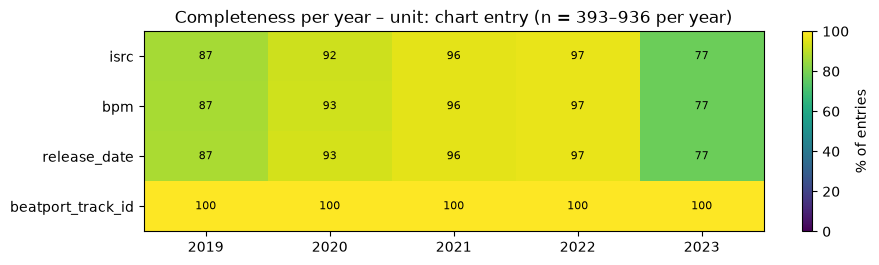

In [15]:
fig, ax = plt.subplots(figsize=(10, 2.6))
im = ax.imshow(relative.T, aspect="auto", cmap="viridis", vmin=0, vmax=100)   # fixed 0–100 → colours stay comparable
ax.set_xticks(range(len(relative)), relative.index)
ax.set_yticks(range(len(EXAMPLE_COLS)), EXAMPLE_COLS)
for (i, j), v in np.ndenumerate(relative.T.to_numpy()):                     # write the value into each cell
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="w" if v < 60 else "k")
fig.colorbar(im, ax=ax, label="% of entries")
ax.set_title(f"Completeness per year – unit: chart entry (n = {n.min()}–{n.max()} per year)")
plt.show()

**Plotting rules:** say what 100 % is (unit and n), fix the scale to 0–100 %, one variable per row/line.
A heatmap is compact for many variables × years; for 3 variables, lines or grouped bars work just as well.

### 5.3 · Example 2: the unit matters (toy data you can check by hand)
Six chart entries, four artists. Which share of the gender information is "complete"?

In [16]:
toy = pd.DataFrame({"year":   [2013, 2013, 2013, 2014, 2014, 2014],
                    "rank":   [1, 2, 3, 1, 2, 3],
                    "artist": ["A", "A", "B", "A", "C", "D"],
                    "gender": ["female", "female", None, "female", None, "male"]})

has = toy["gender"].notna()
entry_level = has.groupby(toy["year"]).mean() * 100              # unit: chart entry
artists = toy.drop_duplicates(["year", "artist"])                # each artist once per year
artist_level = artists["gender"].notna().groupby(artists["year"]).mean() * 100   # unit: artist

comparison = pd.DataFrame({"entries with gender (%)": entry_level, "artists with gender (%)": artist_level,
                           "artists with gender (n)": artists["gender"].notna().groupby(artists["year"]).sum()})
comparison.round(1)

,entries with gender (%),artists with gender (%),artists with gender (n)
year,,,
2013,66.7,50.0,1
2014,66.7,66.7,2


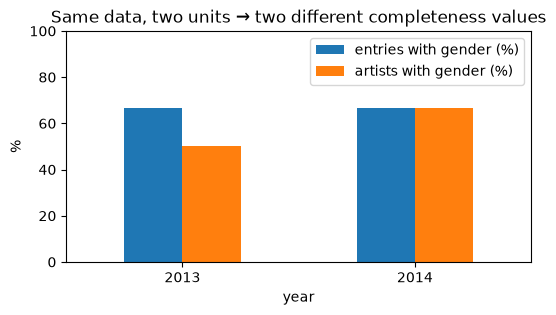

In [17]:
comparison.iloc[:, :2].plot.bar(rot=0, ylim=(0, 100), ylabel="%", figsize=(6, 3),
                                title="Same data, two units → two different completeness values")
plt.show()

- 2013: 2 of 3 **entries** (67 %), but only 1 of 2 **artists** (50 %) – artist A charts twice and has gender, B doesn't.
- 2013 → 2014 **absolute**: 1 → 2 artists with gender ("doubled"); **relative**: 50 → 67 %. Absolute numbers only compare when n is the same.
- Which unit is right depends on the question: "How well are the *artists* of my genre documented?" → artist level.
  "For how many *chart entries* can I compute gender diversity?" → entry level. Say which one you use, and n.

---
## References
**String matching**
- Jaro, M. A. (1989). Advances in record-linkage methodology as applied to matching the 1985 census of Tampa, Florida. *Journal of the American Statistical Association, 84*(406), 414–420.
- Winkler, W. E. (1990). String comparator metrics and enhanced decision rules in the Fellegi-Sunter model of record linkage. *Proceedings of the Section on Survey Research Methods, American Statistical Association*, 354–359.
- RapidFuzz documentation: https://rapidfuzz.github.io/RapidFuzz/

**APIs**
- Discogs API (authentication, rate limits, search): https://www.discogs.com/developers · client: https://python3-discogs-client.readthedocs.io
- MusicBrainz API (rate limiting, ISRC lookup, search): https://musicbrainz.org/doc/MusicBrainz_API · client: https://python-musicbrainzngs.readthedocs.io

**Self-similarity, novelty, distances**
- Foote, J. (1999). Visualizing music and audio using self-similarity. *Proceedings of ACM Multimedia*, 77–80.
- Foote, J. (2000). Automatic audio segmentation using a measure of audio novelty. *Proceedings of IEEE ICME*, 452–455.
- Mahalanobis, P. C. (1936). On the generalised distance in statistics. *Proceedings of the National Institute of Sciences of India, 2*(1), 49–55.
- Müller, M. (2021). *Fundamentals of Music Processing* (2nd ed.), ch. 4 "Music Structure Analysis". Springer. Notebooks: https://www.audiolabs-erlangen.de/FMP

**Essentia and mood models**
- Bogdanov, D., et al. (2013). Essentia: An audio analysis library for music information retrieval. *Proceedings of ISMIR*, 493–498.
- Alonso-Jiménez, P., Bogdanov, D., Pons, J., & Serra, X. (2020). TensorFlow audio models in Essentia. *Proceedings of IEEE ICASSP*, 266–270.
- Alonso-Jiménez, P., Serra, X., & Bogdanov, D. (2022). Music representation learning based on editorial metadata from Discogs. *Proceedings of ISMIR*.
- Laurier, C., Meyers, O., Serrà, J., Blech, M., & Herrera, P. (2009). Music mood annotator design and integration. *Proceedings of CBMI*.
- Essentia models and example code: https://essentia.upf.edu/models.html